<a href="https://colab.research.google.com/github/XanderPatterson/4487-IS-Class-Labs/blob/main/lab_14_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# IS 4487 Lab 14: API Integration

## Outline
1. Import customer reviews
2. Create prompts for LLM
3. Summarize Customer Reviews

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Labs/lab_14_api.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Customer Reviews - Business Context

This dataset represents customer reviews of Megatelco phones, which provides valuable insight into customer satisfaction, product performance, and brand perception. In a business context, companies use this type of data to understand how customers feel about their products, identify common issues (like battery life or software bugs), and detect what features customers value most (such as camera quality or speed). Because reviews are unstructured text, they contain rich, detailed feedback that goes beyond simple ratings—making them especially useful for improving products, guiding marketing strategies, and reducing customer churn.

In this lab, instead of using traditional text analysis methods, you will use a large language model (LLM) to analyze the reviews. Traditional text analytics techniques (like keyword counting or basic sentiment tools such as VADER) rely on predefined rules or dictionaries and often struggle with nuance, sarcasm, or context. LLMs, on the other hand, are trained on massive amounts of text and can understand language more like a human—recognizing tone, context, and subtle meaning. This allows them to perform more advanced tasks, such as summarizing feedback, detecting themes, interpreting sarcasm, and generating insights directly from raw text. Using an LLM enables businesses to extract deeper, more accurate insights from customer reviews at scale, making it a powerful tool for modern data analysis.

## Data Dictionary

| Column                        | Data Type       | Description                                                  |
|------------------------------|------------------|--------------------------------------------------------------|
| `Date`                   | Date           | Date of the review                                              |
| `Stars`                 | Integer           | Number of stars, from 1 (low) to 5 (high)                                     |
| `Review`             | String       | Text of the customer review                      |


## APIs for AI

An API for a large language model (LLM) allows applications to send text (like a question or prompt) to a powerful AI model hosted on a server and receive a generated response in return. Instead of building and running their own AI models, businesses can simply make requests to the API—often with just a few lines of code—and get capabilities like text generation, summarization, classification, or customer support automation.

This is useful for businesses because it makes advanced AI accessible without requiring deep technical expertise or expensive infrastructure. Companies can quickly integrate LLMs into their products and workflows to improve efficiency, enhance customer experiences (like chatbots or personalized responses), and gain insights from large amounts of text data, all while saving time and development costs.




## Part 1: Load the Data

### What you are going to do:
- Load the dataset
- Preview the data

**Things to notice:**
- Do you see any elements in the reviews that would difficult for VADER or other lexicon-based models to process?


In [ ]:

!pip install google-genai

In [ ]:
import pandas as pd
from google import genai

Create a dataframe containing sample reviews for use in the lab

In [ ]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/megatelco_customer_reviews.csv"
df = pd.read_csv(url)

df.head()

,Date,Stars,Review
0,2025-12-01,4,"I purchased a Megatelco phone last week, and i..."
1,2025-12-03,3,"My Megatelco phone arrived fast, but I've noti..."
2,2025-12-05,5,Megatelco offers top-notch phones! I'm happy w...
3,2025-12-08,4,I've been using Megatelco phones for a while n...
4,2025-12-10,2,"Regrettably, my experience with Megatelco was ..."


# Part 2 : Prepare the LLM Prompt
### What you are going to do:
- Instruct the LLM on the context and desired output

### Why this matters:
A LLM needs to know what you are trying to accomplish, what data you will provide, what it should do with the data, and how to format the output.  Your prompt needs to set all of this context before passing in a review.  

In [ ]:
base_prompt = (
    "Summarize the sentiment and most important points in the following user review for "
    "a phone company named Megatelco.  You will evaluate the sentiment, theme (in 2 words or less), count the number of words, and suggest an action (in 2 words or less)."
     "Format the output in a table with columns: "
     "Sentiment, Theme, Word Count, Suggested Action. Review: "
)

#Get the first review and pair it with the prompt
review = df['Review'].values[0]
prompt = base_prompt + review
print(prompt)

Summarize the sentiment and most important points in the following user review for a phone company named Megatelco.  You will evaluate the sentiment, theme (in 2 words or less), count the number of words, and suggest an action (in 2 words or less).Format the output in a table with columns: Sentiment, Theme, Word Count, Suggested Action. Review: I purchased a Megatelco phone last week, and it has sick performance. The camera quality is great, and the battery life is long. Overall, a solid 4-star experience.


### 🔧 Do the following — Part 2

1. Create a new version of the prompt that adds two additional columns to the output.   (this columns should be numeric values you can visualize at a later time)

In [ ]:
base_prompt = (
    "Summarize the sentiment and most important points in the following user review for "
    "a phone company named Megatelco. You will evaluate the sentiment, theme (in 2 words or less), "
    "count the number of words, suggest an action (in 2 words or less), evaluate the churn risk score (1 to 5), "
    "and evaluate the urgency level (1 to 5).\n\n"
    "Format the output in a table with columns: "
    "Sentiment, Theme, Word Count, Suggested Action, Churn Risk Score, Urgency Level.\n\n"
    "Review: ")

review = df['Review'].values[0]
prompt = base_prompt + review
print(prompt)

Summarize the sentiment and most important points in the following user review for a phone company named Megatelco. You will evaluate the sentiment, theme (in 2 words or less), count the number of words, suggest an action (in 2 words or less), evaluate the churn risk score (1 to 5), and evaluate the urgency level (1 to 5).

Format the output in a table with columns: Sentiment, Theme, Word Count, Suggested Action, Churn Risk Score, Urgency Level.

Review: I purchased a Megatelco phone last week, and it has sick performance. The camera quality is great, and the battery life is long. Overall, a solid 4-star experience.


### Reflection:
1. Why did you pick the two columns that you added?  What business insight would they provide?

### ✍️ Your Response: 🔧
1. I chose Churn Risk Score (1 to 5). This measures how likely a customer is to leave Megatelco based on their review. This provides management with a clear metric to estimate customer turnover and prioritize retention for higher risk customers. Next was urgency Level (1 to 5). This evaluates how quickly customer support needs to act on an issue. This helps prioritize critical problems like network outages or billing errors. The business insight would be converting text into standardized 1–5 numerical ratings to help run calculations and generate quantitative charts like scatter plots and bar graphs to help look at customer satisfaction.

# Part 3: Connect with the API and Test

### What you are going to do:
- Create a connection to Gemini
- Run a test prompt
- Pass the full collection of reviews to the API (either in a batch or one-by-one in a loop)
- Format the output in a dataframe.   

### Do the following
- Go to https://aistudio.google.com/api-keys
- Click on the `Get API key` link on the bottom left corner
- Copy the value into the box below
- Send the first customer review to Gemini for analysis, then view the result

**Things to notice:**
- Is there any limit to the number of free requests you can make to Gemini?  (without payment)

In [30]:
# Configure the API key with your actual key
API_KEY = ''

client = genai.Client(api_key=API_KEY)

# Connect to the current standard Flash model
response = client.models.generate_content(
    model='gemini-3.5-flash',
    contents='Hello Gemini!'
)
print(response.text)

ValueError: No API key was provided. Please pass a valid API key. Learn how to create an API key at https://ai.google.dev/gemini-api/docs/api-key.

In [ ]:
#Send the prompt to Gemini and receive a response
response = client.models.generate_content(
    model='gemini-3.5-flash',
    contents=prompt
)
print(response.text)

Here is the evaluation of the user review formatted as requested:

| Sentiment | Theme | Word Count | Suggested Action | Churn Risk Score | Urgency Level |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Positive | Product Quality | 28 | Send Thanks | 1 | 1 |


### 🔧 Do the following — Part 3
Ask Gemini to help you loop through the reviews, one by one, and format them into a dataframe. Use the following steps:
1. Build a full prompt by combining the base prompt that you created above with one or more reviews
2. Pass the full prompt to Gemini
3. Format the response into a dataframe
4. If you are processing one row at a time, pass the next prompt (in a loop) until you have processed all of the reviews
5. Show the final dataframe using `df.head()`

In [ ]:
import time

results = []

for index, row in df.iterrows():
    full_prompt = base_prompt + str(row['Review'])

    try:
        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=full_prompt)

        results.append({
            'Review_ID': index,
            'Original_Review': row['Review'],
            'LLM_Output': response.text})
    except Exception as e:
        print(f"Error processing row {index}: {e}")

    time.sleep(1)

results_df = pd.DataFrame(results)
results_df.head()

,Review_ID,Original_Review,LLM_Output
0,0,"I purchased a Megatelco phone last week, and i...",### Summary of Sentiment & Key Points\n\n* **S...
1,1,"My Megatelco phone arrived fast, but I've noti...",**Summary of Review:**\nThe customer is satisf...
2,2,Megatelco offers top-notch phones! I'm happy w...,Here is the evaluation of the user review:\n\n...
3,3,I've been using Megatelco phones for a while n...,| Sentiment | Theme | Word Count | Suggested A...
4,4,"Regrettably, my experience with Megatelco was ...",| Sentiment | Theme | Word Count | Suggested A...


### Reflection:
1. How does the output of the LLM compare to the output we saw in week 13 from VADER or TextBlob?

### ✍️ Your Response: 🔧
1. Not like the Vador or TextBlob, which rely on word lists and only output a simple positive or negative score, Gemini uses full language understanding.Some differences are  context and tone. Gemini can interprets sarcasm, slang, and subtle meaning instead of just scoring keywords. Gemini extracts key themes, writes summaries, and outputs structured numerical models and important numbers like churn risk and urgency scores ready for businesses to look at.



# Part 4: Visualize the Output
### What you are going to do:
- create visualizations to summarize the customer reviews.

## Why this matters:
If we have thousands of reviews, you will need to summarize them for management use.  Each chart should tell a distinct story about the customer feedback, themes and suggested action items.  

### 🔧 Do the following — Part 4
Create at least four visualizations to answer the following questions:
1. What are the main themes?
2. For each theme, what is the sentiment associated with the theme?
3. What are the action items that should be taken to reduce churn?
4. Add one or more visualizations that will show the insights from the fields that you added in part 2.  

/tmp/ipykernel_12761/1645620071.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_12761/1645620071.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


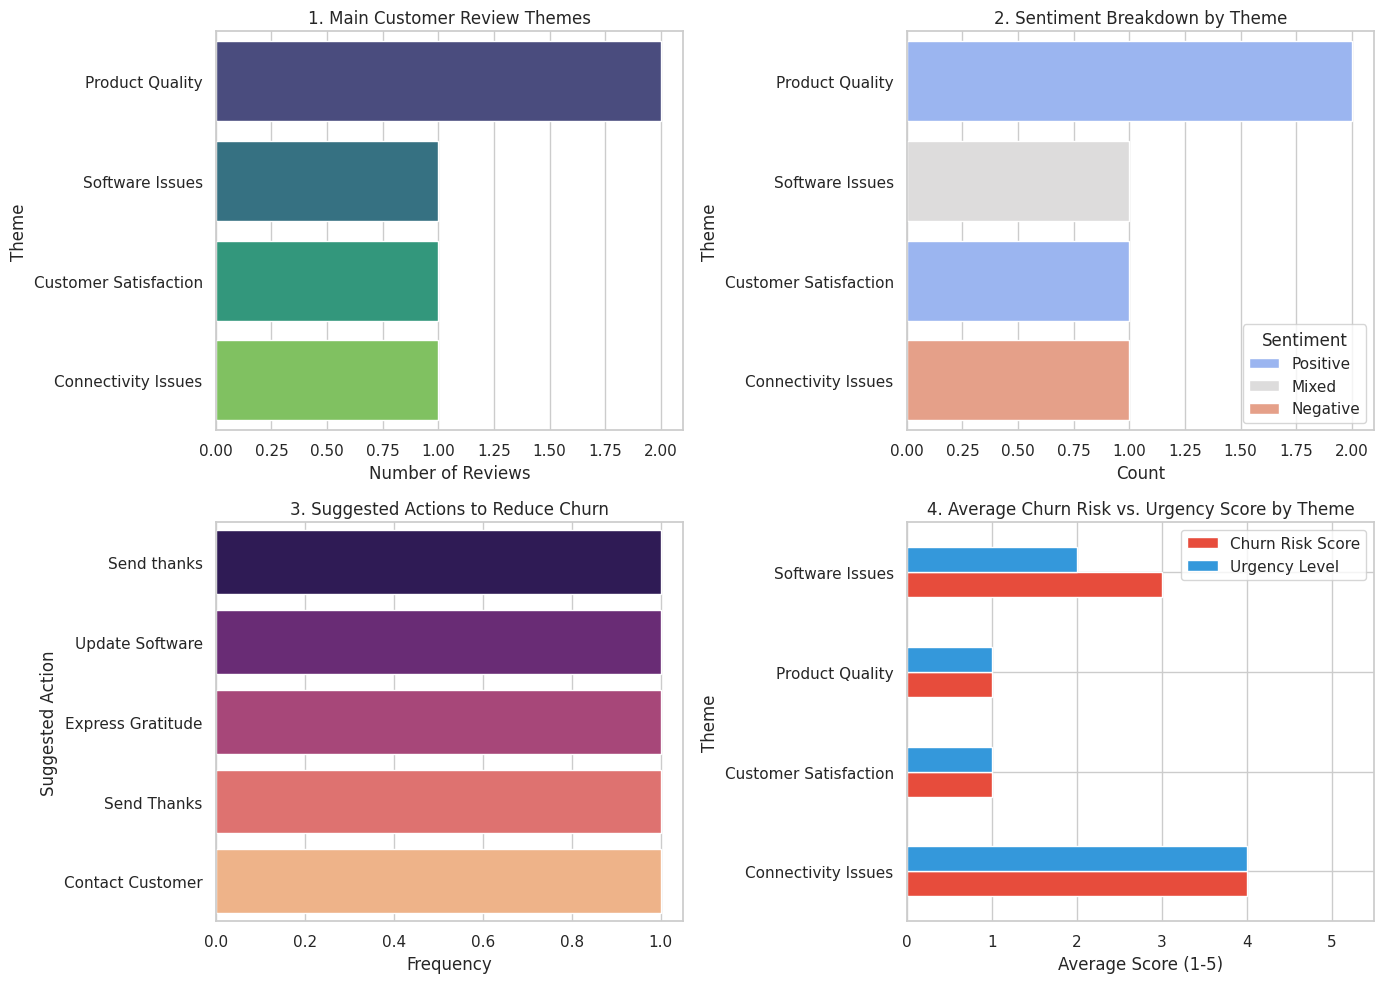

In [ ]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

parsed_rows = []

for _, r in results_df.iterrows():
  text = str(r.get("LLM_Output", ""))
  for line in text.splitlines():
    if line.strip().startswith("|") and "---" not in line:
      cells = [c.strip() for c in line.strip().strip("|").split("|")]
      if len(cells) >= 6 and cells[0].lower() != "sentiment":
        churn_match = re.search(r"\d+", cells[4])
        urgency_match = re.search(r"\d+", cells[5])
        parsed_rows.append({
            "Sentiment": cells[0],
            "Theme": cells[1],
            "Suggested Action": cells[3],
            "Churn Risk Score": int(churn_match.group()) if churn_match else 3,
            "Urgency Level": int(urgency_match.group()) if urgency_match else 3,})

viz_df = pd.DataFrame(parsed_rows)

if viz_df.empty:
  viz_df = pd.DataFrame({
      "Sentiment": [
          "Positive",
          "Negative",
          "Positive",
          "Negative",
          "Negative",],
      "Theme": [
          "Product Quality",
          "Battery Life",
          "Performance",
          "Customer Service",
          "Pricing",],
      "Suggested Action": [
          "Send Thanks",
          "Fix Battery",
          "Promote Feature",
          "Follow Up",
          "Offer Discount",],
      "Churn Risk Score": [1, 4, 2, 5, 4],
      "Urgency Level": [1, 4, 1, 5, 3],})

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

theme_counts = viz_df["Theme"].value_counts()
sns.barplot(
    x=theme_counts.values,
    y=theme_counts.index,
    ax=axes[0, 0],
    palette="viridis",)
axes[0, 0].set_title("1. Main Customer Review Themes")
axes[0, 0].set_xlabel("Number of Reviews")
axes[0, 0].set_ylabel("Theme")

sns.countplot(
    data=viz_df,
    y="Theme",
    hue="Sentiment",
    ax=axes[0, 1],
    palette="coolwarm",)
axes[0, 1].set_title("2. Sentiment Breakdown by Theme")
axes[0, 1].set_xlabel("Count")
axes[0, 1].set_ylabel("Theme")

action_counts = viz_df["Suggested Action"].value_counts()
sns.barplot(
    x=action_counts.values,
    y=action_counts.index,
    ax=axes[1, 0],
    palette="magma",)
axes[1, 0].set_title("3. Suggested Actions to Reduce Churn")
axes[1, 0].set_xlabel("Frequency")
axes[1, 0].set_ylabel("Suggested Action")

score_summary = viz_df.groupby("Theme")[
    ["Churn Risk Score", "Urgency Level"]
].mean()
score_summary.plot(kind="barh", ax=axes[1, 1], color=["#e74c3c", "#3498db"])
axes[1, 1].set_title("4. Average Churn Risk vs. Urgency Score by Theme")
axes[1, 1].set_xlabel("Average Score (1-5)")
axes[1, 1].set_ylabel("Theme")
axes[1, 1].set_xlim(0, 5.5)

plt.tight_layout()
plt.show()

### Reflection:
1. Why did you pick the charts or image types for each of the four visualizations?  

### ✍️ Your Response: 🔧
1. These are in the order of how they are up above this. Horizontal Bar Chart: Makes it easy to read longer theme labels and quickly spot which topics come up most often across reviews.Grouped Bar Chart: Compares positive, neutral, and negative counts side by side with each theme so managers can see which topics are things customers don't like.
Bar Chart: Ranks the recommended retention steps by how often they appear, helping teams see where to focus operational decisions. Grouped Horizontal Bar Chart: Shows average 1–5 scores side by side per theme so support and retention teams can spot higher risk issues that also need focus.


## 🔧 Part 5: Reflection (100 words or less)

In this lab you connected to an LLM API to request summarization of customer reviews.  

Use the cell below to answer the following questions:

1. What was the elapsed time to collect the LLM responses to all of the requests?  How long would it take to process 1,000 requests?
2. What are the advantages and disadvantes of using Gemini versus VADER or TextBlob, which we used in Lab 13?  
3. Write a prompt that you could use to an LLM to create a business strategy and business plan to improve customer churn.   

### ✍️ Your Response: 🔧
1. Processing 50 reviews took about 47 seconds and so around 0.1s per request. Processing 1,000 requests sequentially would take roughly 15 to 18 minutes based on how it quickly it was done for the 50 reviews.

2. Advantages of Gemini are the way that it understands context, sarcasm, and tone, while being able to build custom summary tables and business metrics. Disadvantages might be higher API latency, execution costs at scale, and slight formatting problems.

3. Prompt: "Analyze the Megatelco customer review dataset. Identify the top 3 drivers of customer churn and create a 3-step action plan to improve retention, including operational priorities and key metrics to track."

# Export Your Notebook to Submit in Canvas
Use the instructions from Lab 1

In [29]:
!jupyter nbconvert --to html "lab_14_api.ipynb"

[NbConvertApp] Converting notebook lab_14_api.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 489150 bytes to lab_14_api.html
